## Logistic Regression

AZ: Describe the model WIP!

The model is trained and evaluated in the following steps:

1. **Features and target:** `Gallstone Status` is the target for the moddel. All other columns in `dataset_df` can be used as predictors/features
2. **Train/test split:** The data is split into training and test sets. we have to stratify the target to balance both sets.
3. TODO: **Scaling:** Features are standardized to minimum ans maximun values of 0 to 1, so the logistic regression return more reliable values.
4. **Model fitting:** A `LogisticRegression` model is fitted on the training data.
5. **Evaluation:** Test-set predictions are scored with accuracy, a confusion matrix, and a classification report (precision, recall, F1).

Install libraries if necessary

In [13]:
# %pip install nbimporter nbformat


Import libraries 

In [14]:
from src.data_loader import load_data
from pathlib import Path
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report


Add configurations

In [27]:
DATA_PATH = Path("dataset-uci.csv")
TARGET = "Gallstone Status"
CLASS_NAMES = ["Without gallstones", "With gallstones"]  # 0, 1

PREFERED_FEATURES = [
    'Vitamin D',
    'C-Reactive Protein (CRP)',
    'Total Body Fat Ratio (TBFR) (%)',
    'Bone Mass (BM)',
    'Hemoglobin (HGB)',
    'Extracellular Fluid/Total Body Water (ECF/TBW)',
    'Hyperlipidemia'
]

RANDOM_STATE = 42   # one seed for every random operation -> reproducible results
TEST_SIZE = 0.20    # 20 % held out, never touched until the final evaluation
MAX_ITERATIONS = 10000 # maximum number of iterations for the logistic regression solver
CV_SPLITS = 5       # folds per cross-validation round
CV_REPEATS = 10 

In [16]:
dataset_df = load_data(DATA_PATH,TARGET)
print(f"Shape: {dataset_df.shape[0]} rows x {dataset_df.shape[1]} columns")
dataset_df.head()

Shape: 319 rows x 39 columns


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


In [17]:
print(f"Missing values : {dataset_df.isna().sum().sum()}")
print(f"Duplicate rows : {dataset_df.duplicated().sum()}")
print("\nClass balance:")
print(dataset_df[TARGET].value_counts().rename(index=dict(enumerate(CLASS_NAMES))))

Missing values : 0
Duplicate rows : 0

Class balance:
Gallstone Status
Without gallstones    161
With gallstones       158
Name: count, dtype: int64


### Features and target

Use `Gallstone Status` as the binary target variable. Use every other column in `dataset_df` as a predictor, excluding the target to prevent data leakage.

In [ ]:
target = TARGET
prefered_features = PREFERED_FEATURES

all_features = dataset_df.columns.tolist()

y = dataset_df[target].astype(int)

X = dataset_df[prefered_features]

# All features except the target
#X = dataset_df[all_features].drop(columns=[target])


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)   

logreg = LogisticRegression(max_iter=MAX_ITERATIONS, random_state=RANDOM_STATE)
logreg.fit(X_train, y_train)
score = logreg.score(X_test, y_test)

y_pred = logreg.predict(X_test)

print("Logistic Regression Score:", score)
print("Logistic Regression prediction:", y_pred)

Logistic Regression Score: 0.84375
Logistic Regression prediction: [0 1 0 1 0 0 0 1 0 0 1 0 1 0 1 0 0 0 1 1 1 0 1 0 0 1 1 0 0 0 0 0 1 1 0 0 0
 0 0 1 0 0 1 1 0 0 0 1 1 0 0 1 1 0 0 1 0 0 0 0 1 0 0 0]
Confusion Matrix:
[[32  1]
 [ 9 22]]


Confusion matrix for the logistic regression model


In [ ]:
cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cnf_matrix)

Text(0.5, 427.9555555555555, 'Predicted label')

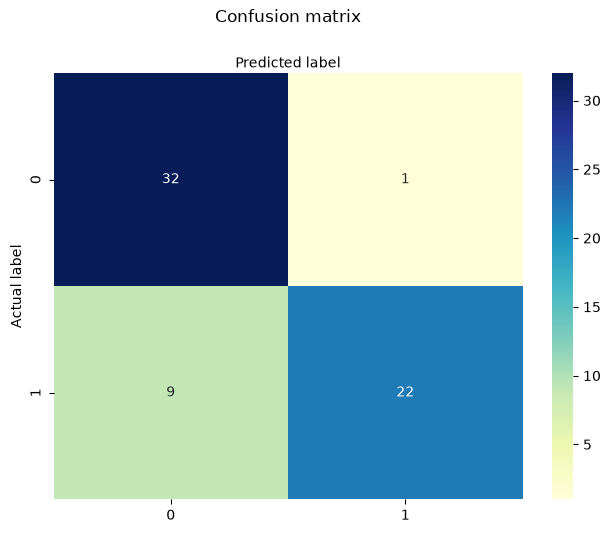

In [22]:
class_names=[0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
# create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

In [23]:
target_names = ['without Gallstone', 'with Gallstone']
print(classification_report(y_test, y_pred, target_names=target_names))

                   precision    recall  f1-score   support

without Gallstone       0.78      0.97      0.86        33
   with Gallstone       0.96      0.71      0.81        31

         accuracy                           0.84        64
        macro avg       0.87      0.84      0.84        64
     weighted avg       0.87      0.84      0.84        64



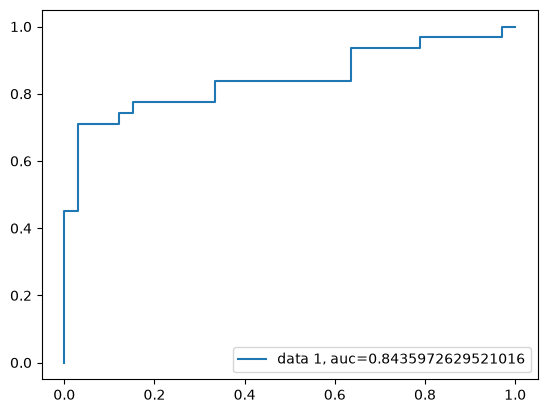

In [24]:
y_pred_proba = logreg.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.legend(loc=4)
plt.show()